# Student Placement Prediction using a Decision Tree

In this notebook we build a complete machine learning project step by step.
We use simple code and explain every step in simple English.

In [43]:
!pip install -U scikit-learn==1.9.1

In [44]:
import sklearn
print(sklearn.__version__)

1.9.1


In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

---
## Step 1: Problem

**Real-life story:** A college placement cell wants to know which students are likely to get a job placement.
If they know this early, they can give extra help (mock interviews, practice tests, mentoring) to the students who need it.

**What we are predicting:** `placement_status` (Placed or Not Placed)

**Type of problem:** Classification, because the answer is one of two classes.

**What we use to predict (features):**
- Student details: gender, branch, extracurricular activities
- Habits: study hours, sleep hours, internet usage
- Performance: attendance, assignments completed, previous score, exam score

**Two types of mistakes the model can make**
- It says "Placed" but the student is not placed: the student may miss the extra help.
- It says "Not Placed" but the student is placed: the college wastes some effort.

---
## Step 2: Data + EDA (Find patterns)

EDA means **Exploratory Data Analysis**.
It is like meeting a new student for the first time: first you look, ask questions and understand, then you decide what to do.

### 2.1 Load the data

In [46]:
df = pd.read_csv('student_performance_dataset.csv')
df.head()

,student_id,gender,branch,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,extracurricular,exam_score,placement_status
0,STU01978,Female,Mechanical,1.5,68.2,6.7,2.6,15.0,63.6,Yes,60.8,Placed
1,STU03881,Male,Mechanical,5.0,80.9,5.5,6.2,12.0,55.4,No,58.8,Not Placed
2,STU00053,Female,CSE,0.8,69.4,7.4,3.6,NaN,43.2,No,44.0,Not Placed
3,STU02552,Female,Commerce,1.3,77.1,7.4,3.6,NaN,76.9,Yes,55.5,Placed
4,STU02247,Male,IT,0.0,46.8,7.4,5.6,4.0,49.7,Yes,41.6,Not Placed


In [47]:
print(df["placement_status"].value_counts())

placement_status
Not Placed    5116
Placed        4884
Name: count, dtype: int64


### 2.2 Understand the columns

| Column | Meaning |
|---|---|
| `student_id` | Unique ID of the student (only a label, not useful for prediction) |
| `gender` | Male or Female |
| `branch` | CSE, IT, ECE, Mechanical, Civil, Commerce |
| `study_hours` | Study hours per day |
| `attendance` | Attendance in percent |
| `sleep_hours` | Sleep hours per day |
| `internet_usage` | Internet use in hours per day |
| `assignments_completed` | Number of assignments completed |
| `previous_score` | Marks in the previous exam |
| `extracurricular` | Does the student take part in extra activities? |
| `exam_score` | Latest exam marks |
| `placement_status` | **Target**: Placed or Not Placed |

In [48]:
# Data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             10000 non-null  object 
 1   gender                 10000 non-null  object 
 2   branch                 9901 non-null   object 
 3   study_hours            9699 non-null   float64
 4   attendance             9600 non-null   float64
 5   sleep_hours            9702 non-null   float64
 6   internet_usage         9696 non-null   float64
 7   assignments_completed  9751 non-null   float64
 8   previous_score         9652 non-null   float64
 9   extracurricular        10000 non-null  object 
 10  exam_score             10000 non-null  float64
 11  placement_status       10000 non-null  object 
dtypes: float64(7), object(5)
memory usage: 937.6+ KB


In [49]:
# Quick summary of the number columns
df.describe()

,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score
count,9699.000000,9600.000000,9702.000000,9696.000000,9751.000000,9652.000000,10000.000000
mean,3.487277,75.787323,6.804556,4.495153,12.835812,61.782553,60.555980
std,1.630787,10.962674,1.114314,1.687334,4.129272,13.031526,14.234672
min,0.000000,33.900000,1.000000,0.200000,0.000000,20.000000,0.000000
25%,2.400000,68.400000,6.100000,3.400000,10.000000,52.800000,50.700000
50%,3.400000,75.700000,6.800000,4.500000,13.000000,61.900000,60.500000
75%,4.500000,83.400000,7.600000,5.600000,16.000000,70.700000,70.100000
max,21.300000,100.000000,14.000000,21.500000,20.000000,100.000000,100.000000


In [50]:
# How many missing values are in each column?
df.isnull().sum()

,0
student_id,0
gender,0
branch,99
study_hours,301
attendance,400
sleep_hours,298
internet_usage,304
assignments_completed,249
previous_score,348
extracurricular,0


In [51]:
# Are there duplicate rows?
df.duplicated().sum()

np.int64(50)

In [52]:
# check Columns purity
cat_col = df.select_dtypes(include='object').columns
cat_col

for col in cat_col:
  print(col,df[col].nunique())
  print()

student_id 9950

gender 6

branch 21

extracurricular 2

placement_status 2



### What is wrong with this data?

Real-world data is never perfect. Here we can see:

1. **Missing values** in many columns (study hours, attendance, sleep hours, and more).
2. **Duplicate rows**, the same student appears twice.
3. **Gender is written in many ways**: `Male`, `male`, `M`, `Female`, `female`, `F`.
4. **Branch has spelling problems**: `CSE`, `cse`, ` CSE ` (with extra spaces), `MECHANICAL`, `mechanical`.
5. **Impossible values (outliers)**: check `study_hours`, `sleep_hours` and `internet_usage` in the table above.
   Nobody can study 21 hours every day!

We will fix these in Step 3 and Step 4.

### 2.3 Is our target balanced?

In [53]:
df['placement_status'].value_counts()

,count
placement_status,
Not Placed,5116
Placed,4884


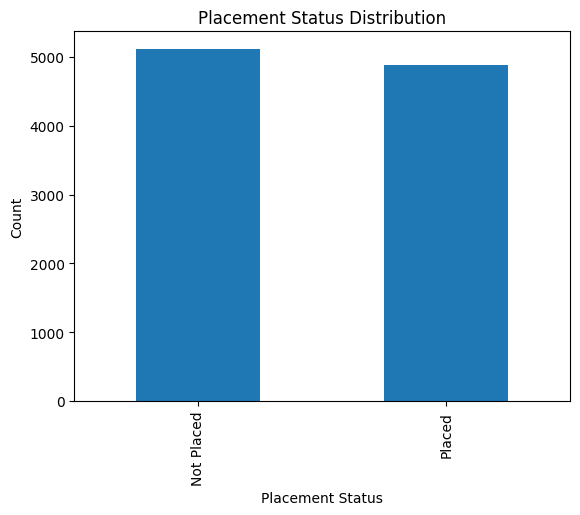

In [54]:
df['placement_status'].value_counts().plot(kind='bar')
plt.title('Placement Status Distribution')
plt.xlabel('Placement Status')
plt.ylabel('Count')
plt.show()

In [55]:
df['placement_status'].value_counts(normalize=True) * 100

,proportion
placement_status,
Not Placed,51.16
Placed,48.84


### 2.4 Do placed students look different?
Let us compare the average of every number column for the two groups.

In [56]:
# Group by num_col to placement_status
df.groupby('placement_status').mean(numeric_only=True)

,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score
placement_status,,,,,,,
Not Placed,2.890603,70.524177,6.775308,4.953032,10.478549,54.363594,51.830219
Placed,4.111519,81.249331,6.835060,4.015022,15.304430,69.512270,69.696233


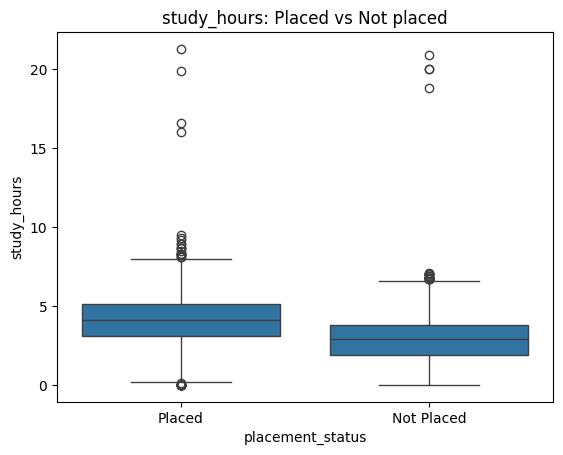

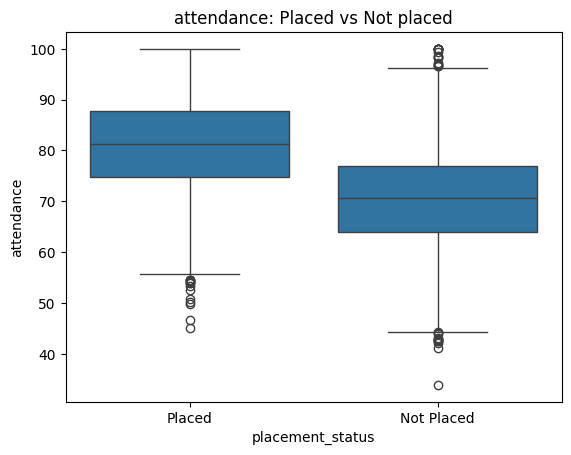

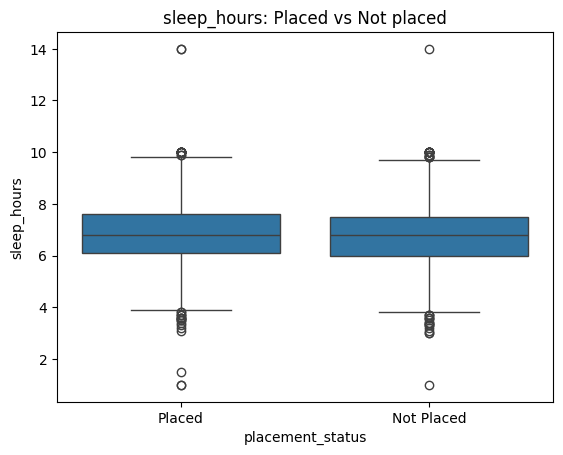

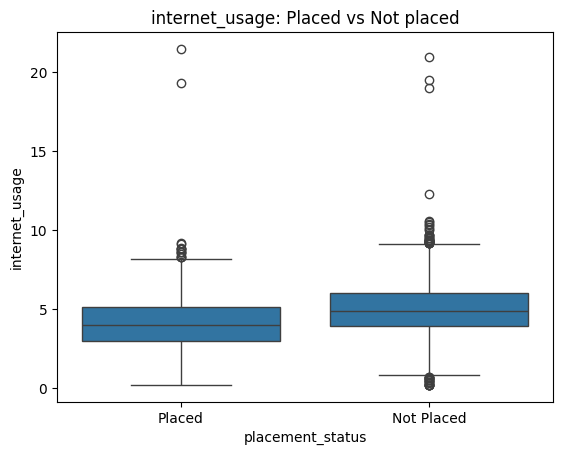

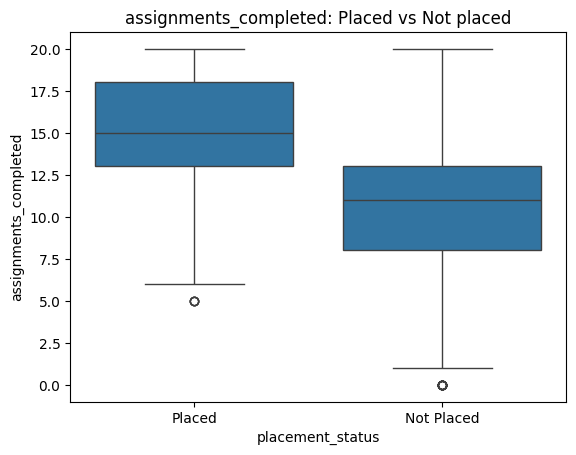

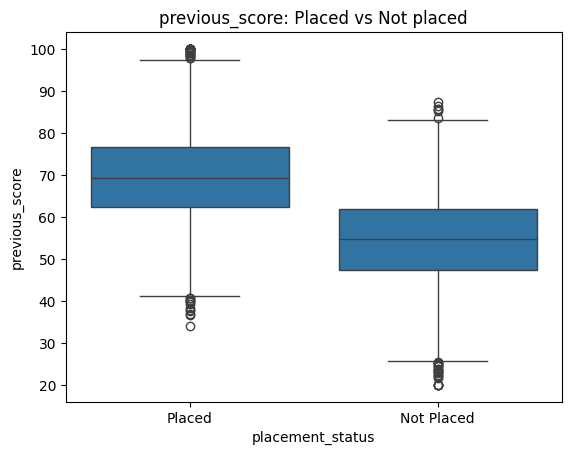

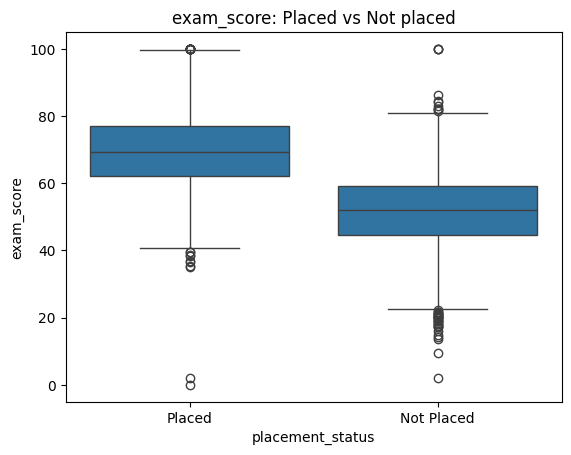

In [57]:
# Box plots: compare Placed and Not Placed for each number column
num_col = df.select_dtypes(include='number').columns

for col in num_col:
  sns.boxplot(x='placement_status', y=col, data=df)
  plt.title(f'{col}: Placed vs Not placed')
  plt.show()

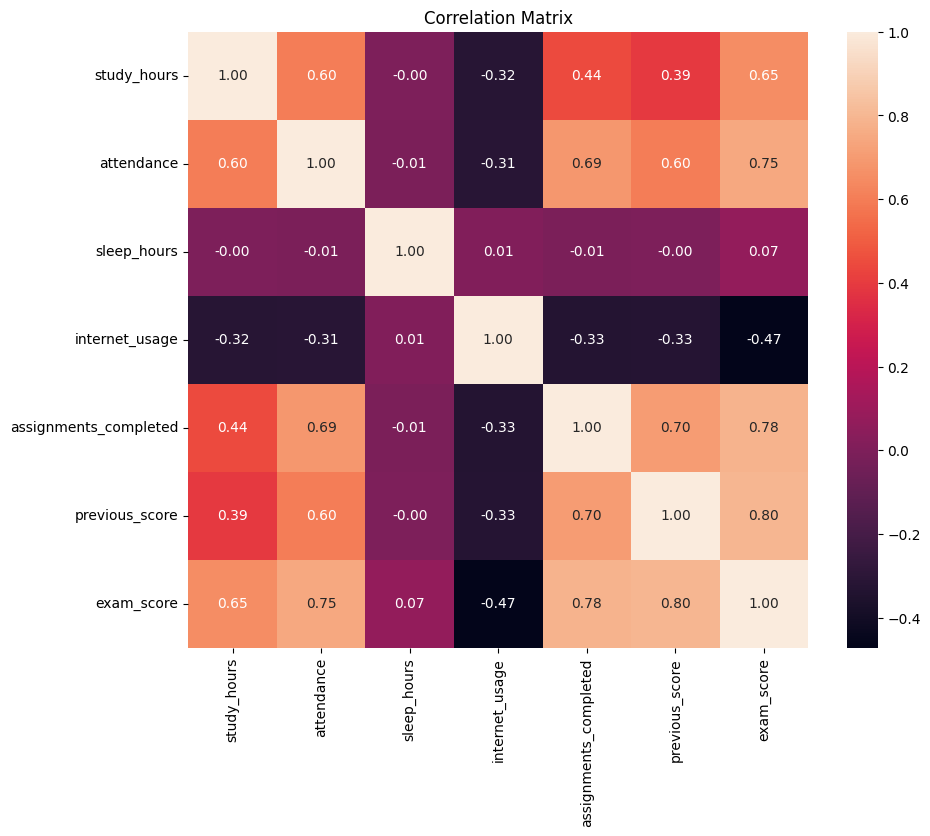

In [58]:
# Correlation: which number columns move together?
corr = df.select_dtypes(include='number').corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

---
## Step 3: Clean data

Rule: **never change the original data**. We work on a copy, so we can always go back.

We will do 5 cleaning jobs:
1. Remove duplicate rows
2. Drop `student_id` (it is only a label)
3. Fix the `gender` column
4. Fix the `branch` column
5. Fix impossible values (outliers)



In [59]:
# Make a copy so the original df stays safe
df_copy = df.copy()

# Job 1: Remove duplicate rows
df_copy = df_copy.drop_duplicates()

# Check remaining duplicates
df_copy.duplicated().sum()

# Job 1.0: Remove null values
df_copy = df_copy.dropna()

# Check remaining null values
df_copy.isnull().sum()

,0
student_id,0
gender,0
branch,0
study_hours,0
attendance,0
sleep_hours,0
internet_usage,0
assignments_completed,0
previous_score,0
extracurricular,0


In [60]:
print("Original rows:", len(df))
print("After removing duplicates:", len(df_copy.drop_duplicates()))
print("After removing nulls:", len(df_copy))

Original rows: 10000
After removing duplicates: 8139
After removing nulls: 8139


In [61]:
df_copy.columns

Index(['student_id', 'gender', 'branch', 'study_hours', 'attendance',
       'sleep_hours', 'internet_usage', 'assignments_completed',
       'previous_score', 'extracurricular', 'exam_score', 'placement_status'],
      dtype='object')

In [62]:
# Job 2: student_id is only a label. It does not help to predict placement.
df_copy = df_copy.drop(columns=['student_id'])
df_copy.head()

,gender,branch,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,extracurricular,exam_score,placement_status
0,Female,Mechanical,1.5,68.2,6.7,2.6,15.0,63.6,Yes,60.8,Placed
1,Male,Mechanical,5.0,80.9,5.5,6.2,12.0,55.4,No,58.8,Not Placed
4,Male,IT,0.0,46.8,7.4,5.6,4.0,49.7,Yes,41.6,Not Placed
5,Male,IT,2.9,68.4,6.9,6.7,8.0,54.0,No,46.4,Not Placed
6,Female,Mechanical,5.0,82.0,5.0,5.0,11.0,56.4,Yes,58.0,Placed


In [63]:
df_copy['gender'].unique()

array(['Female', 'Male', 'F', 'female', 'M', 'male'], dtype=object)

In [64]:
# Job 3: fix gender
# strip() removes extra spaces, lower() makes small letters, map() gives one clean name
df_copy['gender'] = df_copy['gender'].str.strip().str.lower().map({'male':'Male','m':'Male','female':'Female','f':'Female'})

In [65]:
# Job 4: fix branch
# Remove extra spaces and make everything CAPITAL letters, so ' cse ' becomes 'CSE'
df_copy['branch'] = df_copy['branch'].str.strip().str.upper()

df_copy.head()

,gender,branch,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,extracurricular,exam_score,placement_status
0,Female,MECHANICAL,1.5,68.2,6.7,2.6,15.0,63.6,Yes,60.8,Placed
1,Male,MECHANICAL,5.0,80.9,5.5,6.2,12.0,55.4,No,58.8,Not Placed
4,Male,IT,0.0,46.8,7.4,5.6,4.0,49.7,Yes,41.6,Not Placed
5,Male,IT,2.9,68.4,6.9,6.7,8.0,54.0,No,46.4,Not Placed
6,Female,MECHANICAL,5.0,82.0,5.0,5.0,11.0,56.4,Yes,58.0,Placed


In [66]:
# Verifying
df_copy['branch'].unique()

array(['MECHANICAL', 'IT', 'CSE', 'CIVIL', 'ECE', 'COMMERCE'],
      dtype=object)

In [67]:
# Job 5: fix impossible values with clip()
# clip(0, 12) means: anything above 12 becomes 12, anything below 0 becomes 0

# df_clean["study_hours"]
# df_clean["sleep_hours"]
# df_clean["internet_usage"]

df_copy[['study_hours', 'sleep_hours', 'internet_usage']] = df_copy[['study_hours', 'sleep_hours', 'internet_usage']].clip(0, 12)
df_copy.head()

,gender,branch,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,extracurricular,exam_score,placement_status
0,Female,MECHANICAL,1.5,68.2,6.7,2.6,15.0,63.6,Yes,60.8,Placed
1,Male,MECHANICAL,5.0,80.9,5.5,6.2,12.0,55.4,No,58.8,Not Placed
4,Male,IT,0.0,46.8,7.4,5.6,4.0,49.7,Yes,41.6,Not Placed
5,Male,IT,2.9,68.4,6.9,6.7,8.0,54.0,No,46.4,Not Placed
6,Female,MECHANICAL,5.0,82.0,5.0,5.0,11.0,56.4,Yes,58.0,Placed


In [68]:
df_copy[['study_hours', 'sleep_hours', 'internet_usage']].describe()

,study_hours,sleep_hours,internet_usage
count,8139.000000,8139.000000,8139.000000
mean,3.487050,6.810284,4.497788
std,1.578313,1.106609,1.671754
min,0.000000,1.000000,0.200000
25%,2.400000,6.100000,3.400000
50%,3.400000,6.800000,4.500000
75%,4.500000,7.600000,5.600000
max,12.000000,12.000000,12.000000


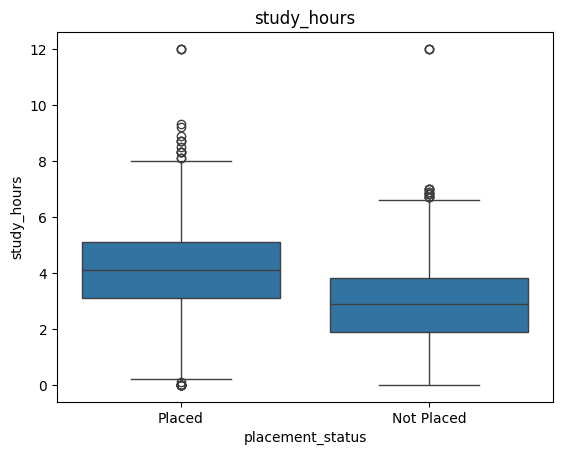

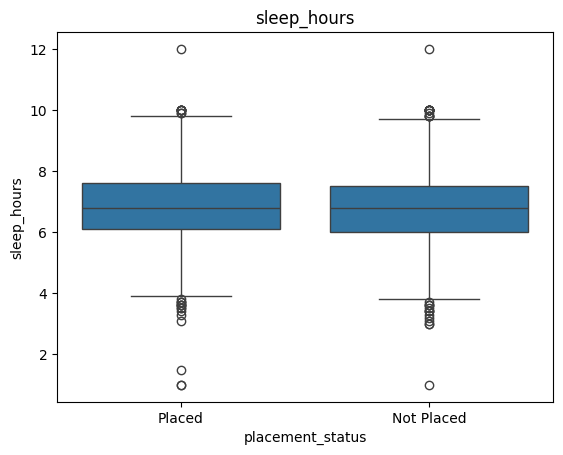

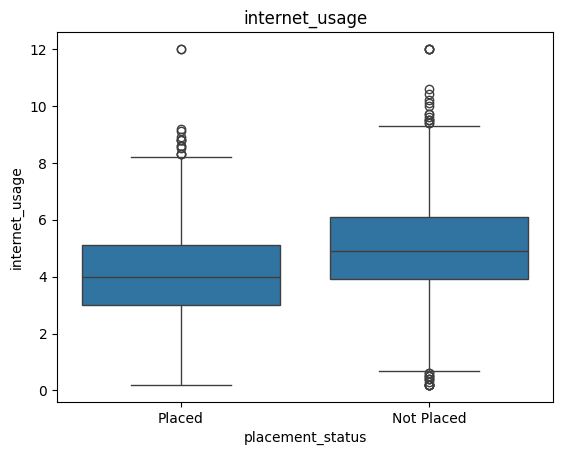

In [69]:
# Quick look at the cleaned categories
# Box plots: compare Placed and Not Placed for each number column
num_col = ['study_hours', 'sleep_hours', 'internet_usage']

for col in num_col:
    sns.boxplot(x="placement_status", y=col, data=df_copy)
    plt.title(col)
    plt.show()

Cleaning is done. Values are now consistent and there are no impossible numbers.
The missing values are still there. We fix them next.

In [70]:
df_copy.isnull().sum()

,0
gender,0
branch,0
study_hours,0
attendance,0
sleep_hours,0
internet_usage,0
assignments_completed,0
previous_score,0
extracurricular,0
exam_score,0


---
## Step 4: Preprocessing

A decision tree needs clean numbers. Preprocessing has 4 small jobs:

1. **Separate X and y.** `X` = the inputs, `y` = the answer we want to predict.
2. **Split into train and test (80% / 20%).**
   *Real-life example:* Students learn from practice papers (train data) and the final exam (test data) has questions they have never seen. The test data tells us the truth.
3. **Convert text to numbers (one-hot encoding).**
   The column `branch` becomes separate columns like `branch_CSE = 1 or 0`, `branch_IT = 1 or 0`, and so on.

**Do we need scaling?** No. Decision trees ask questions like "attendance above 75?", so the scale of the numbers does not matter.

---
## Step 4: Preprocessing — corrected Pipeline approach

Instead of manually creating dummy columns and label encoders, we use a scikit-learn Pipeline.
The Pipeline keeps preprocessing and the Decision Tree together, so FastAPI can later send the original student fields directly.

**Why this is important:** the same preprocessing used during training is automatically applied during prediction. This prevents feature-name mismatch errors such as `branch` vs `branch_CSE`.


In [71]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import joblib


In [72]:
# Use the cleaned data before manual encoding.
# df_copy contains cleaned text values such as Male/Female and CSE/IT/ECE/etc.

X_pipeline = df_copy.drop(columns=['placement_status'])

y_pipeline = df_copy['placement_status'].map({
    'Not Placed': 0,
    'Placed': 1
})

print('X shape:', X_pipeline.shape)
print('y shape:', y_pipeline.shape)
print(y_pipeline.value_counts())


X shape: (8139, 10)
y shape: (8139,)
placement_status
0    4149
1    3990
Name: count, dtype: int64


In [73]:
# Columns that contain text/categories
categorical_features = [
    'gender',
    'branch',
    'extracurricular'
]

# Columns that contain numbers
numeric_features = [
    'study_hours',
    'attendance',
    'sleep_hours',
    'internet_usage',
    'assignments_completed',
    'previous_score',
    'exam_score'
]


In [74]:
# Preprocessing for numeric columns
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median'))
    ]
)

# Preprocessing for categorical columns
categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)


### Step 4.1: Train-test split

We keep 80% of the data for training and 20% for testing. `stratify` keeps the class proportions similar in both sets.


In [75]:
X_train, X_test, y_train, y_test = train_test_split(
    X_pipeline,
    y_pipeline,
    test_size=0.2,
    random_state=42,
    stratify=y_pipeline
)

print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('y_train:', y_train.shape)
print('y_test :', y_test.shape)


X_train: (6511, 10)
X_test : (1628, 10)
y_train: (6511,)
y_test : (1628,)


---
## Step 5: Decision Tree Pipeline

The Pipeline performs one-hot encoding and then trains the Decision Tree. No manual `get_dummies()` or `LabelEncoder()` is needed.


In [76]:
decision_tree = DecisionTreeClassifier(
    random_state=42,
    criterion='gini',
    max_depth=3,
    min_samples_leaf=1
)

placement_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', decision_tree)
    ]
)

placement_model.fit(X_train, y_train)

print('Pipeline trained successfully.')


Pipeline trained successfully.


In [77]:
y_pred = placement_model.predict(X_test)

print('Train accuracy:', accuracy_score(y_train, placement_model.predict(X_train)))
print('Test accuracy :', accuracy_score(y_test, y_pred))


Train accuracy: 0.8001843034864076
Test accuracy : 0.8108108108108109


---
## Step 6: Tune the Pipeline

The hyperparameters are now applied to the Decision Tree inside the Pipeline using the `classifier__` prefix.


In [78]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'classifier__max_depth': [3, 5, 7, 10],
    'classifier__min_samples_leaf': [1, 2, 5, 10],
    'classifier__criterion': ['gini', 'entropy']
}

random_search = RandomizedSearchCV(
    estimator=placement_model,
    param_distributions=param_grid,
    n_iter=10,
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

best_model = random_search.best_estimator_

print('Best parameters:')
print(random_search.best_params_)


Best parameters:
{'classifier__min_samples_leaf': 2, 'classifier__max_depth': 7, 'classifier__criterion': 'gini'}


Accuracy : 0.8028255528255528
Precision: 0.8142292490118577
Recall   : 0.7744360902255639
F1 Score : 0.7938342967244701
Confusion Matrix:
[[689 141]
 [180 618]]


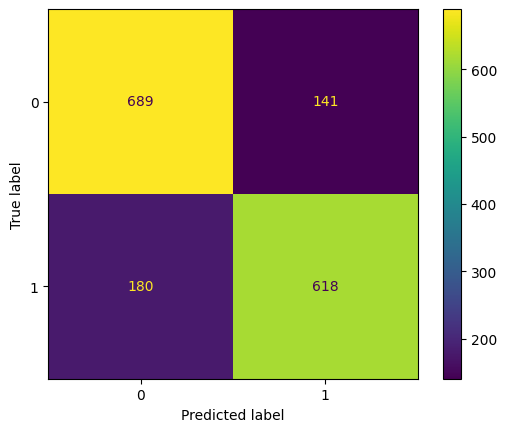

In [79]:
y_pred = best_model.predict(X_test)

print('Accuracy :', accuracy_score(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred))
print('Recall   :', recall_score(y_test, y_pred))
print('F1 Score :', f1_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
print('Confusion Matrix:')
print(cm)

ConfusionMatrixDisplay(confusion_matrix=cm).plot()
plt.show()


---
## Step 7: Explain the model

Feature importance is extracted from the Decision Tree inside the Pipeline. The feature names are obtained from the fitted OneHotEncoder.


In [80]:
feature_names = best_model.named_steps['preprocessor'].get_feature_names_out()
importances = best_model.named_steps['classifier'].feature_importances_

feature_importance = pd.Series(
    importances,
    index=feature_names
).sort_values(ascending=False)

print(feature_importance)


num__exam_score               0.704813
cat__extracurricular_No       0.096645
num__previous_score           0.066466
num__assignments_completed    0.059293
num__internet_usage           0.014692
num__study_hours              0.014049
num__attendance               0.013205
cat__branch_CSE               0.011967
num__sleep_hours              0.010089
cat__branch_MECHANICAL        0.004252
cat__branch_ECE               0.001703
cat__branch_CIVIL             0.001509
cat__branch_COMMERCE          0.001311
cat__branch_IT                0.000008
cat__gender_Female            0.000000
cat__gender_Male              0.000000
cat__extracurricular_Yes      0.000000
dtype: float64


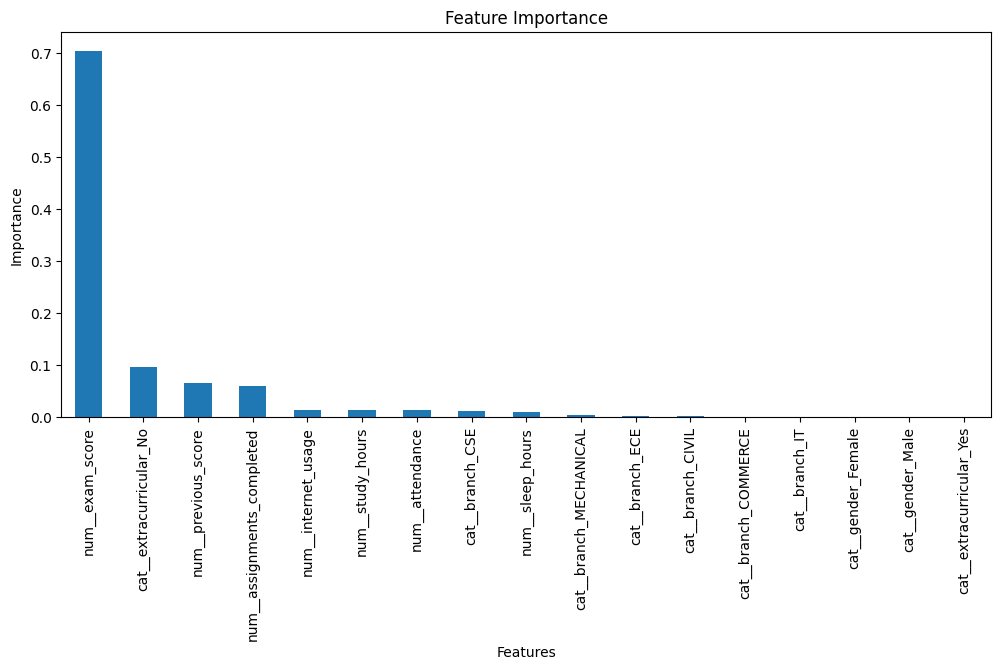

In [81]:
feature_importance.plot(
    kind='bar',
    figsize=(12, 5)
)

plt.title('Feature Importance')
plt.xlabel('Features')
plt.ylabel('Importance')
plt.xticks(rotation=90)
plt.show()


---
## Step 8: Test one new student

The important point is that we pass the original columns. The Pipeline performs the encoding automatically.


In [82]:
test_student = pd.DataFrame([{
    'gender': 'Male',
    'branch': 'CSE',
    'study_hours': 5,
    'attendance': 85,
    'sleep_hours': 7,
    'internet_usage': 3,
    'assignments_completed': 15,
    'previous_score': 75,
    'extracurricular': 'Yes',
    'exam_score': 80
}])

prediction = best_model.predict(test_student)[0]
probabilities = best_model.predict_proba(test_student)[0]
predicted_probability = probabilities[int(prediction)]

result = 'Placed' if prediction == 1 else 'Not Placed'

print('Prediction:', result)
print('Probability:', round(float(predicted_probability) * 100, 2), '%')


Prediction: Placed
Probability: 100.0 %


---
## Step 9: Save the model

We save the complete Pipeline, not just the Decision Tree. This means FastAPI receives raw student data and the saved Pipeline handles preprocessing automatically.


In [83]:
joblib.dump(best_model, 'placement_model.joblib')
print('Saved: placement_model.joblib')


Saved: placement_model.joblib


In [84]:
# Verify that the saved model is a Pipeline
loaded_model = joblib.load('placement_model.joblib')
print(type(loaded_model))

<class 'sklearn.pipeline.Pipeline'>


### Next: FastAPI

Move the generated `placement_model.joblib` file into the FastAPI project folder. The FastAPI app will use the same raw fields as `test_student` above.


In [85]:
from google.colab import files

files.download("placement_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>